## 1. Import Essential Libraries
Importing `pandas` for data manipulation, and preprocessing tools from `scikit-learn` for label encoding and feature scaling.

In [1]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler

## 2. Load Training and Testing Datasets
Loading the dataset files for both model training and evaluation to inspect their structure.

In [2]:
from pathlib import Path

DATA_DIR = Path("data")

train_df = pd.read_csv(DATA_DIR / "KDDTrain.csv")
test_df = pd.read_csv(DATA_DIR / "KDDTest.csv")

train_df.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack,level
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


## 3. Data Pre-processing and Categorical Encoding
Identifying the categorical (object type) columns in the training and testing datasets before converting them to numerical formats.

In [3]:
print('The object columns in the train data is: ', train_df.select_dtypes(include=['object']).columns)
print('The object columns in the test  data is: ', test_df.select_dtypes(include=['object']).columns)

The object columns in the train data is:  Index(['protocol_type', 'service', 'flag', 'attack'], dtype='object')
The object columns in the test  data is:  Index(['protocol_type', 'service', 'flag', 'attack'], dtype='object')


In [4]:
# Check the nulls:
print(train_df.isna().any().any(),',' , test_df.isna().any().any())

False , False


### Categorical Feature Encoding
Using `LabelEncoder` to convert categorical variables (`protocol_type`, `service`, `flag`) into numerical values so they can be processed by the neural network.

In [5]:
from sklearn.preprocessing import LabelEncoder

label_encoders = {}

categorical_cols = train_df.select_dtypes(
    include=['object']
).columns.tolist()

for col in categorical_cols:
    if col == 'attack':
        continue

    encoder = LabelEncoder()

    train_df[col] = encoder.fit_transform(train_df[col])
    test_df[col] = encoder.transform(test_df[col])

    label_encoders[col] = encoder

train_df.select_dtypes(include=['object']).head(2)

,attack
0,normal
1,normal


### Define Features and Target for Binary Classification
Converting the target variable `attack` into a binary label (`is_attack` where normal = 0 and attack = 1), and splitting the data into features (X) and targets (y).

In [6]:
train_df['is_attack'] = train_df['attack'].apply(lambda x: 0 if x == 'normal' else 1)
test_df['is_attack'] = test_df['attack'].apply(lambda x: 0 if x == 'normal' else 1)

X_train = train_df.drop(['attack', 'is_attack', 'level'], axis=1)
y_train = train_df['is_attack']

X_test = test_df.drop(['attack', 'is_attack', 'level'], axis=1)
y_test = test_df['is_attack']

### Feature Scaling
Applying `StandardScaler` to normalize the numerical features. This ensures training stability and better convergence for the deep learning model.

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train shape:", X_train_scaled.shape)
print("X_test shape:", X_test_scaled.shape)

X_train shape: (125973, 41)
X_test shape: (22544, 41)


## 4. Deep Learning Model with Keras
Designing, building, and training a Deep Neural Network (DNN) model for Network Intrusion Detection (NIDS).

### Import TensorFlow and Keras Components

In [8]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from sklearn.metrics import classification_report, accuracy_score
from tensorflow.keras.callbacks import EarlyStopping


### Build the Deep Learning Model Architecture

In [9]:
model = Sequential([
    Input(shape=(41,)),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

In [10]:
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         5,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,745 (61.50 KB)

 Trainable params: 15,745 (61.50 KB)

 Non-trainable params: 0 (0.00 B)

### Train the Model
Training the neural network using an Adam optimizer and Binary Crossentropy loss. We implement `EarlyStopping` to prevent overfitting and restore the best weights.

In [11]:
train = model.fit(X_train_scaled, y_train,
                    epochs=40,
                    batch_size=64,
                    validation_split=0.1,
                    verbose=1,
                  callbacks=[tf.keras.callbacks.EarlyStopping(
                       patience=5,
                       monitor='val_accuracy',
                       restore_best_weights=True)]
                )

Epoch 1/40
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 14s 6ms/step - accuracy: 0.9759 - loss: 0.0727 - val_accuracy: 0.9900 - val_loss: 0.0282
Epoch 2/40
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9878 - loss: 0.0360 - val_accuracy: 0.9917 - val_loss: 0.0254
Epoch 3/40
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9894 - loss: 0.0298 - val_accuracy: 0.9938 - val_loss: 0.0194
Epoch 4/40
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 20s 9ms/step - accuracy: 0.9904 - loss: 0.0269 - val_accuracy: 0.9925 - val_loss: 0.0191
Epoch 5/40
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9914 - loss: 0.0242 - val_accuracy: 0.9944 - val_loss: 0.0184
Epoch 6/40
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9921 - loss: 0.0229 - val_accuracy: 0.9946 - val_loss: 0.0179
Epoch 7/40
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9923 - loss: 0.0223 - val_accuracy: 0.9951 - val_loss: 0.0165
Epoch 8/40
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9928 - loss: 0.0208

## 5. Model Evaluation and Performance Metrics
Evaluating the trained model on unseen test data, computing overall test accuracy, and displaying the classification report and confusion matrix.

In [12]:
y_pred_probs = model.predict(X_test_scaled)
y_pred = (y_pred_probs >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
print(f"\nTest Accuracy: {acc * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

705/705 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step

Test Accuracy: 78.17%

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.97      0.79      9711
           1       0.97      0.64      0.77     12833

    accuracy                           0.78     22544
   macro avg       0.82      0.81      0.78     22544
weighted avg       0.84      0.78      0.78     22544



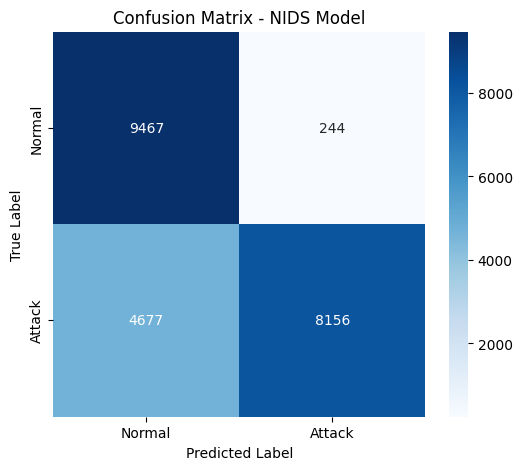

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Attack'],
            yticklabels=['Normal', 'Attack'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - NIDS Model')
plt.savefig('confusion_matrix.png')
plt.show()

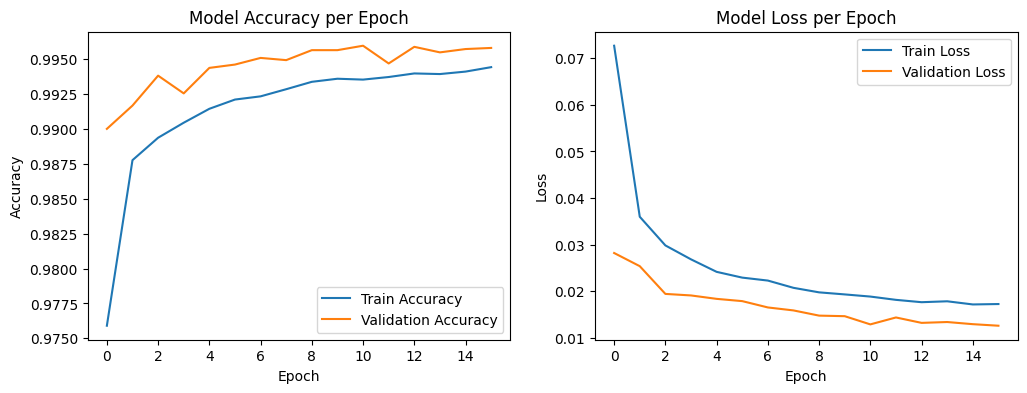

In [14]:
plt.figure(figsize=(12, 4))


plt.subplot(1, 2, 1)
plt.plot(train.history['accuracy'], label='Train Accuracy')
plt.plot(train.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(train.history['loss'], label='Train Loss')
plt.plot(train.history['val_loss'], label='Validation Loss')
plt.title('Model Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.savefig('training_curves.png')
plt.show()